## Step 1: Loading & First Inspection
In this step, we import the core data science libraries, load the raw dataset from `data/raw/`, inspect the dimensions (rows/columns), preview sample records, and verify column data types.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("../src/data/student_mental_health.csv")

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [5]:
df.shape

(2000, 17)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [25]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


# Exploratory Data Analysis (EDA)

Check data quality before building our models.

In [16]:
display(pd.DataFrame({
    "Missing ": df.isnull().sum(),
    "Precentage" : (df.isnull().mean() * 100).round(2)
}))

# duuplicates 
print("duuplicated roows :" , df.duplicated().sum())

# uniique

display(df.nunique().to_frame("Unique Values"))

,Missing,Precentage
Student_ID,0,0.00
Age,0,0.00
Gender,0,0.00
Year_of_Study,0,0.00
Sleep_Hours,62,3.10
Study_Hours_Per_Week,0,0.00
GPA,38,1.90
Social_Media_Hours,58,2.90
Screen_Time_Hours,0,0.00
Physical_Activity,0,0.00


duuplicated roows : 0


,Unique Values
Student_ID,2000
Age,13
Gender,3
Year_of_Study,5
Sleep_Hours,66
Study_Hours_Per_Week,284
GPA,182
Social_Media_Hours,71
Screen_Time_Hours,95
Physical_Activity,3


## 2. Descriptive Statistics

Explore numerical and categorical columns to understand their values and distributions.

In [19]:
print(df["Student_ID"].dtype)
print(df.select_dtypes(include=np.number).columns.tolist())

str
['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']


In [23]:
numeric_columns = df.select_dtypes(include=np.number).columns.drop("Student_ID",errors="ignore")

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,2000.0,21.131500,2.139275,17.0,20.000,21.00,23.00,29.00
Year_of_Study,2000.0,2.630000,1.316802,1.0,1.000,2.00,4.00,5.00
Sleep_Hours,1938.0,6.758875,1.127072,3.3,6.000,6.70,7.60,10.00
Study_Hours_Per_Week,2000.0,19.997900,5.719274,2.4,16.000,19.80,24.00,38.30
GPA,1962.0,2.562503,0.343993,1.5,2.320,2.56,2.79,3.66
Social_Media_Hours,1942.0,6.013955,1.153422,2.1,5.225,6.00,6.70,10.00
Screen_Time_Hours,2000.0,8.548500,1.657571,3.3,7.400,8.50,9.70,14.00
Financial_Stress,1909.0,5.956260,1.893941,1.4,4.500,6.10,7.40,10.00
Family_Support,1946.0,6.518345,1.844639,1.7,5.100,6.70,8.00,9.90
Attendance_Rate,1953.0,85.080236,7.224118,54.4,80.300,85.10,90.00,100.00


In [24]:
categorrical_cols = df.select_dtypes(include="object").columns

display(df[categorrical_cols].describe().T)

/tmp/ipykernel_850349/2778497599.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorrical_cols = df.select_dtypes(include="object").columns


,count,unique,top,freq
Student_ID,2000,2000,STU0001,1
Gender,2000,3,Female,971
Physical_Activity,2000,3,Moderate,906
Part_Time_Job,2000,2,No,1289
Diet_Quality,1931,3,Average,860
Previous_Mental_Health_History,2000,2,No,1408
Mental_Health_Risk,2000,3,High,680


## 3. Target Distribution

Analyze the distribution of the target variable and check for class imbalance.

In [26]:
target_counts = df["Mental_Health_Risk"].value_counts()

display(target_counts)

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

In [27]:
target_percentages = df["Mental_Health_Risk"].value_counts(normalize=True) * 100

display(target_percentages.round(2))

Mental_Health_Risk
High      34.0
Medium    33.0
Low       33.0
Name: proportion, dtype: float64

### Visualize the number of students in each risk category.

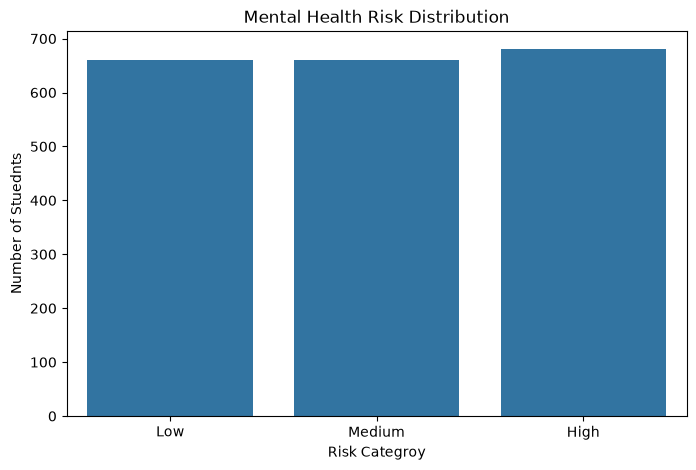

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mental_Health_Risk",
    order=["Low", "Medium" , "High"]
)

plt.title("Mental Health Risk Distribution")
plt.xlabel("Risk Categroy")
plt.ylabel("Number of Stuednts")

plt.show()